# 5. Búsqueda tabú

La búsqueda tabú (*tabu search*) es un método de trayectoria que sale de los óptimos locales de una manera distinta a las del capítulo 4. En cada paso se mueve al mejor vecino de la solución actual, aunque sea peor, y usa una memoria de corto plazo para no deshacer los movimientos recientes. El capítulo presenta la idea y las decisiones de diseño que la componen, qué se prohíbe, por cuánto tiempo y cuándo se levanta la prohibición. Después muestra el comportamiento del método en las reinas y en el agente viajero, el efecto de la permanencia en la lista tabú y una comparación con ILS y GRASP.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

## Instancias y código común

El capítulo usa las instancias de los capítulos anteriores y agrega una mochila de 100 objetos para las comparaciones, porque la de 20 objetos resultó demasiado fácil en el capítulo 4. En la mochila nueva, el valor de cada objeto es su peso más 10, una estructura que se comenta al final del capítulo. Como los pesos son enteros, el valor óptimo se puede calcular con programación dinámica sobre la capacidad. La función `optimo_mochila_pd` lo hace y, para comprobarla, recupera el óptimo de la mochila de 20 objetos que el capítulo 1 encontró por enumeración.

La celda oculta siguiente repite las clases de los problemas, el presupuesto de evaluaciones, la búsqueda local, ILS y GRASP del capítulo 4, con dos cambios. Cada problema tiene ahora dos métodos para la lista tabú, `atributos` y `es_tabu`, que se explican más adelante. En las reinas, el cambio de costo de un intercambio se calcula solo con las dos reinas que se mueven, lo que es mucho más rápido que contar de nuevo los conflictos de todo el tablero; la celda comprueba que el resultado coincide con el cálculo completo.

In [2]:
np.random.seed(42)
random.seed(42)

# Mismas instancias de los capítulos 1, 3 y 4
N_OBJETOS = 20
pesos20 = np.random.randint(1, 31, size=N_OBJETOS)
valores20 = np.random.randint(1, 51, size=N_OBJETOS)
capacidad20 = int(0.4 * pesos20.sum())

N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))

# Mochila de 100 objetos con valores correlacionados con los pesos
rng = np.random.default_rng(2026)
pesos100 = rng.integers(1, 101, size=100)
valores100 = pesos100 + 10
capacidad100 = int(0.5 * pesos100.sum())


def optimo_mochila_pd(pesos, valores, capacidad):
    """Valor óptimo de la mochila 0-1 por programación dinámica sobre la capacidad."""
    mejor = np.zeros(capacidad + 1, dtype=np.int64)
    for w, v in zip(pesos, valores):
        mejor[w:] = np.maximum(mejor[w:], mejor[:-w] + v) if w > 0 else mejor[w:]
    return int(mejor[capacidad])


OPTIMO_MOCHILA100 = optimo_mochila_pd(pesos100, valores100, capacidad100)
print(f"Mochila de 100 objetos: peso total {pesos100.sum()}, capacidad {capacidad100}, "
      f"valor óptimo por programación dinámica {OPTIMO_MOCHILA100}")
print(f"Comprobación con la mochila de 20 objetos: {optimo_mochila_pd(pesos20, valores20, capacidad20)} (capítulo 1: 402)")

Mochila de 100 objetos: peso total 5028, capacidad 2514, valor óptimo por programación dinámica 3204
Comprobación con la mochila de 20 objetos: 402 (capítulo 1: 402)


In [3]:
class Mochila:
    """Mochila 0-1. Costo: valor con signo cambiado. Movimientos: flip e intercambio."""

    def __init__(self, pesos, valores, capacidad):
        self.pesos, self.valores, self.capacidad = pesos, valores, capacidad
        self.n = len(pesos)

    def aleatoria(self):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        for i in np.random.permutation(self.n):
            if np.random.random() < 0.5 and peso + self.pesos[i] <= self.capacidad:
                x[i] = 1
                peso += self.pesos[i]
        return x

    def costo(self, x):
        return -int(np.dot(x, self.valores))

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [('flip', i) for i in range(self.n)] + [('swap', i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        r = random.randrange(self.n + len(dentro) * len(fuera))
        if r < self.n:
            return ('flip', r)
        r -= self.n
        return ('swap', dentro[r // len(fuera)], fuera[r % len(fuera)])

    def delta(self, x, mov):
        peso = np.dot(x, self.pesos)
        if mov[0] == 'flip':
            i = mov[1]
            signo = 1 if x[i] == 0 else -1
            if peso + signo * self.pesos[i] > self.capacidad:
                return None
            return -signo * self.valores[i]
        _, i, j = mov
        if peso - self.pesos[i] + self.pesos[j] > self.capacidad:
            return None
        return self.valores[i] - self.valores[j]

    def aplicar(self, x, mov):
        y = x.copy()
        if mov[0] == 'flip':
            y[mov[1]] = 1 - y[mov[1]]
        else:
            y[mov[1]], y[mov[2]] = 0, 1
        return y

    def perturbar(self, x, k=3):
        y = x.copy()
        for i in np.random.choice(self.n, size=k, replace=False):
            y[i] = 1 - y[i]
        while np.dot(y, self.pesos) > self.capacidad:
            y[np.random.choice(np.flatnonzero(y == 1))] = 0
        return y

    def construir_grasp(self, alfa):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        while True:
            candidatos = [i for i in range(self.n) if x[i] == 0 and peso + self.pesos[i] <= self.capacidad]
            if not candidatos:
                return x
            razon = {i: self.valores[i] / self.pesos[i] for i in candidatos}
            r_max, r_min = max(razon.values()), min(razon.values())
            lrc = [i for i in candidatos if razon[i] >= r_max - alfa * (r_max - r_min)]
            i = random.choice(lrc)
            x[i] = 1
            peso += self.pesos[i]

    # Atributos tabú: los objetos que cambian de estado
    def atributos(self, x, mov):
        return {mov[1]} if mov[0] == 'flip' else {mov[1], mov[2]}

    def es_tabu(self, x, mov, tabu_hasta, iteracion):
        return any(tabu_hasta.get(a, 0) > iteracion for a in self.atributos(x, mov))


class Reinas:
    """n reinas sobre permutaciones. Costo: pares en conflicto. Movimiento: intercambio de dos filas."""

    def __init__(self, n):
        self.n = n

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, s):
        diag1 = Counter(i - f for i, f in enumerate(s))
        diag2 = Counter(i + f for i, f in enumerate(s))
        return sum(c * (c - 1) // 2 for c in diag1.values()) + sum(c * (c - 1) // 2 for c in diag2.values())

    def movimientos(self, s):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 1, self.n)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, s):
        return tuple(sorted(random.sample(range(self.n), 2)))

    def _ataques(self, s, col, fila, excluir):
        """Reinas que atacan en diagonal a una reina en (col, fila), sin contar las columnas excluidas."""
        return sum(1 for c, f in enumerate(s) if c not in excluir and abs(f - fila) == abs(c - col))

    def delta(self, s, mov):
        """Cambio en los conflictos calculado solo con las dos reinas que se mueven."""
        i, j = mov
        antes = (self._ataques(s, i, s[i], (i, j)) + self._ataques(s, j, s[j], (i, j))
                 + (abs(s[i] - s[j]) == j - i))
        despues = (self._ataques(s, i, s[j], (i, j)) + self._ataques(s, j, s[i], (i, j))
                   + (abs(s[j] - s[i]) == j - i))
        return despues - antes

    def aplicar(self, s, mov):
        t = list(s)
        i, j = mov
        t[i], t[j] = t[j], t[i]
        return t

    def perturbar(self, s, k=3):
        t = list(s)
        for _ in range(k):
            i, j = random.sample(range(self.n), 2)
            t[i], t[j] = t[j], t[i]
        return t

    def construir_grasp(self, alfa):
        s, libres = [], set(range(self.n))
        for col in range(self.n):
            ataques = {f: sum(1 for c, g in enumerate(s) if abs(g - f) == col - c) for f in libres}
            a_min, a_max = min(ataques.values()), max(ataques.values())
            lrc = [f for f in libres if ataques[f] <= a_min + alfa * (a_max - a_min)]
            f = random.choice(lrc)
            s.append(f)
            libres.remove(f)
        return s

    # Atributos tabú: la fila que deja cada reina que se mueve (no puede volver a ella)
    def atributos(self, s, mov):
        i, j = mov
        return {(i, s[i]), (j, s[j])}

    def es_tabu(self, s, mov, tabu_hasta, iteracion):
        i, j = mov
        return tabu_hasta.get((i, s[j]), 0) > iteracion or tabu_hasta.get((j, s[i]), 0) > iteracion


class Viajero:
    """Agente viajero. Costo: longitud del recorrido. Movimiento: 2-opt."""

    def __init__(self, distancias):
        self.d = distancias
        self.n = len(distancias)

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, ruta):
        return sum(self.d[ruta[k], ruta[(k + 1) % self.n]] for k in range(self.n))

    def movimientos(self, ruta):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 2, self.n) if not (i == 0 and j == self.n - 1)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, ruta):
        while True:
            i, j = sorted(random.sample(range(self.n), 2))
            if j >= i + 2 and not (i == 0 and j == self.n - 1):
                return (i, j)

    def delta(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return self.d[a, c] + self.d[b, d] - self.d[a, b] - self.d[c, d]

    def aplicar(self, ruta, mov):
        i, j = mov
        return ruta[:i + 1] + ruta[i + 1:j + 1][::-1] + ruta[j + 1:]

    def perturbar(self, ruta, k=None):
        p1, p2, p3 = sorted(random.sample(range(1, self.n), 3))
        return ruta[:p1] + ruta[p2:p3] + ruta[p1:p2] + ruta[p3:]

    def construir_grasp(self, alfa):
        ruta = [random.randrange(self.n)]
        pendientes = set(range(self.n)) - {ruta[0]}
        while pendientes:
            dist = {j: self.d[ruta[-1], j] for j in pendientes}
            d_min, d_max = min(dist.values()), max(dist.values())
            lrc = [j for j in pendientes if dist[j] <= d_min + alfa * (d_max - d_min)]
            j = random.choice(lrc)
            ruta.append(j)
            pendientes.remove(j)
        return ruta

    # Atributos tabú: los arcos que el movimiento quita (no se pueden volver a poner)
    def atributos(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return {frozenset((a, b)), frozenset((c, d))}

    def es_tabu(self, ruta, mov, tabu_hasta, iteracion):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        agregados = (frozenset((a, c)), frozenset((b, d)))
        return any(tabu_hasta.get(arco, 0) > iteracion for arco in agregados)


class Presupuesto:
    """Cuenta las evaluaciones de vecinos y avisa cuando se agotan."""

    def __init__(self, maximo):
        self.maximo, self.usadas = maximo, 0

    def gastar(self, k=1):
        self.usadas += k

    @property
    def agotado(self):
        return self.usadas >= self.maximo


def busqueda_local(prob, x, presupuesto):
    """Primera mejora, como en el capítulo 4."""
    c = prob.costo(x)
    while not presupuesto.agotado:
        mejoro = False
        for mov in prob.movimientos(x):
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = prob.aplicar(x, mov), c + d
                mejoro = True
                break
        if not mejoro:
            break
    return x, c


def busqueda_local_iterada(prob, presupuesto):
    """ILS del capítulo 4."""
    x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
    mejor_x, mejor_c = x, c
    while not presupuesto.agotado:
        y, cy = busqueda_local(prob, prob.perturbar(x), presupuesto)
        if cy <= c:
            x, c = y, cy
            if c < mejor_c:
                mejor_x, mejor_c = x, c
    return mejor_x, mejor_c


def grasp(prob, presupuesto, alfa=0.3):
    """GRASP del capítulo 4."""
    mejor_x, mejor_c = None, math.inf
    while not presupuesto.agotado:
        x0 = prob.construir_grasp(alfa)
        presupuesto.gastar()
        x, c = busqueda_local(prob, x0, presupuesto)
        if c < mejor_c:
            mejor_x, mejor_c = x, c
    return mejor_x, mejor_c


mochila20 = Mochila(pesos20, valores20, capacidad20)
mochila100 = Mochila(pesos100, valores100, capacidad100)
reinas = Reinas(30)
viajero = Viajero(distancias)

# Comprobación del cambio de costo de las reinas contra el cálculo completo
random.seed(0)
np.random.seed(0)
for _ in range(200):
    s = reinas.aleatoria()
    mov = reinas.movimiento_aleatorio(s)
    assert reinas.delta(s, mov) == reinas.costo(reinas.aplicar(s, mov)) - reinas.costo(s)
print("El cambio de costo de las reinas coincide con el cálculo completo en 200 movimientos al azar")

El cambio de costo de las reinas coincide con el cálculo completo en 200 movimientos al azar


## La idea del método

La búsqueda local se detiene cuando ningún vecino mejora la solución actual. La búsqueda tabú no se detiene. En cada iteración evalúa los vecinos de la solución actual y se mueve al mejor, aunque empeore, de modo que en un óptimo local sale del valle por el vecino menos malo. El riesgo es volver. Desde ese vecino peor, el mejor movimiento suele ser el que deshace el anterior, y la búsqueda quedaría oscilando entre dos soluciones. Para evitarlo, guarda en una lista tabú información sobre los movimientos recientes y prohíbe, durante algunas iteraciones, los que los desharían.

Una iteración tiene tres pasos:

1. evaluar los vecinos de la solución actual, todos o una lista de candidatos escogidos al azar;
2. escoger el mejor de esos vecinos entre los que no son tabú y los tabú que cumplen el criterio de aspiración;
3. moverse a ese vecino, aunque sea peor, y actualizar la lista tabú y la mejor solución encontrada.

La búsqueda termina cuando se agota el presupuesto y devuelve la mejor solución encontrada, que no tiene por qué ser la actual.

## Qué se prohíbe

Hay dos maneras de guardar la memoria. La más directa es la lista de las últimas soluciones visitadas, en la que un vecino es tabú si aparece. Es la versión del laboratorio de búsqueda tabú del curso, que guarda los últimos recorridos del agente viajero. Su inconveniente es el costo, porque comparar cada vecino con cada solución de la lista exige recorrer soluciones completas. Además, la lista solo impide volver a esas soluciones exactas y no a otras muy parecidas.

La versión más usada guarda atributos de los movimientos. Después de aplicar un movimiento, la búsqueda prohíbe por un tiempo los movimientos que lo desharían, identificados por un atributo sencillo. Los atributos de este capítulo son los siguientes:

- en la mochila, los objetos que cambiaron de estado, que no se pueden volver a cambiar;
- en las reinas, la fila que deja cada una de las dos reinas que se mueven, a la que esa reina no puede volver;
- en el agente viajero, los dos arcos que quita el movimiento 2-opt, que no se pueden volver a poner.

La permanencia (*tabu tenure*) es el número de iteraciones durante las cuales un atributo queda prohibido. La función `busqueda_tabu` guarda, para cada atributo, la iteración hasta la que es tabú, de modo que no necesita una lista explícita.

Prohibir atributos es más restrictivo que prohibir soluciones, porque un atributo tabú bloquea también soluciones que nunca se visitaron. Por eso se agrega un criterio de aspiración, que admite un movimiento tabú si produce una solución mejor que la mejor encontrada hasta el momento.

In [4]:
def busqueda_tabu(prob, presupuesto, permanencia, muestra=None, x0=None):
    """
    En cada iteración evalúa los vecinos de la solución actual (todos, o una muestra
    aleatoria de tamaño muestra) y se mueve al mejor que no sea tabú, aunque empeore.
    Un movimiento tabú se admite si produce una solución mejor que la mejor encontrada
    (criterio de aspiración). Los atributos del movimiento aplicado quedan prohibidos
    durante permanencia iteraciones.
    """
    x = prob.aleatoria() if x0 is None else x0
    c = prob.costo(x)
    mejor_x, mejor_c = x, c
    tabu_hasta = {}
    iteracion = 0
    historia = []
    while not presupuesto.agotado:
        iteracion += 1
        if muestra is None:
            candidatos = prob.movimientos(x)
        else:
            candidatos = [prob.movimiento_aleatorio(x) for _ in range(muestra)]
        mejor_mov, mejor_d = None, math.inf
        for mov in candidatos:
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is None:
                continue
            if prob.es_tabu(x, mov, tabu_hasta, iteracion) and not (c + d < mejor_c - 1e-9):
                continue  # Tabú y sin aspiración
            if d < mejor_d:
                mejor_mov, mejor_d = mov, d
        if mejor_mov is None:
            continue
        for a in prob.atributos(x, mejor_mov):
            tabu_hasta[a] = iteracion + permanencia
        x, c = prob.aplicar(x, mejor_mov), c + mejor_d
        if c < mejor_c - 1e-9:
            mejor_x, mejor_c = x, c
        historia.append((c, mejor_c))
    return mejor_x, mejor_c, historia

## La búsqueda en marcha

La celda siguiente aplica la búsqueda tabú a las reinas de $30 \times 30$, con una lista de 100 candidatos por iteración, permanencia 10 y 20 000 evaluaciones. En las reinas se usa una lista de candidatos porque, con el vecindario completo de 435 vecinos, el presupuesto alcanzaría para menos de 50 iteraciones. También la aplica al agente viajero de 50 ciudades, con el vecindario 2-opt completo, permanencia 20 y 200 000 evaluaciones. La figura muestra, en cada iteración, el costo de la solución actual y el de la mejor encontrada.

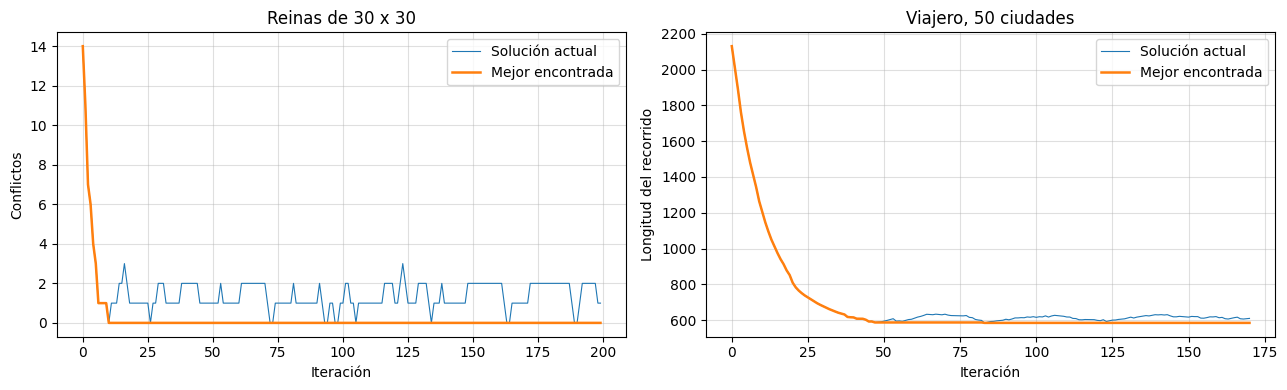

Reinas: 200 iteraciones, 26 movimientos que empeoran, mejor costo 0, alcanzado en la iteración 11
Viajero: 171 iteraciones, 67 movimientos que empeoran, mejor longitud 584.60


In [5]:
random.seed(42)
np.random.seed(42)
_, mejor_reinas, hist_reinas = busqueda_tabu(reinas, Presupuesto(20000), permanencia=10, muestra=100)
_, mejor_viajero, hist_viajero = busqueda_tabu(viajero, Presupuesto(200000), permanencia=20)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, hist, titulo in [(ejes[0], hist_reinas, 'Reinas de 30 x 30'), (ejes[1], hist_viajero, 'Viajero, 50 ciudades')]:
    eje.plot([h[0] for h in hist], linewidth=0.8, label='Solución actual')
    eje.plot([h[1] for h in hist], linewidth=1.8, label='Mejor encontrada')
    eje.set_xlabel('Iteración')
    eje.set_title(titulo)
    eje.grid(True, alpha=0.4)
    eje.legend()
ejes[0].set_ylabel('Conflictos')
ejes[1].set_ylabel('Longitud del recorrido')
plt.tight_layout()
plt.show()

empeoran_r = sum(1 for a, b in zip(hist_reinas, hist_reinas[1:]) if b[0] > a[0])
empeoran_v = sum(1 for a, b in zip(hist_viajero, hist_viajero[1:]) if b[0] > a[0])
print(f"Reinas: {len(hist_reinas)} iteraciones, {empeoran_r} movimientos que empeoran, mejor costo {mejor_reinas}, "
      f"alcanzado en la iteración {next(k for k, h in enumerate(hist_reinas) if h[1] == mejor_reinas) + 1}")
print(f"Viajero: {len(hist_viajero)} iteraciones, {empeoran_v} movimientos que empeoran, mejor longitud {mejor_viajero:.2f}")

En las reinas, la búsqueda llega a cero conflictos en la iteración 11. Como no se detiene al encontrar una solución, la figura muestra también lo que hace después de un óptimo. La solución actual sube a uno, dos o tres conflictos y vuelve a bajar, porque en cada iteración la búsqueda toma el mejor vecino permitido y los movimientos que la devolverían a la solución anterior están prohibidos. En las 200 iteraciones hay 26 movimientos que empeoran la solución.

En el agente viajero, la búsqueda parte de un recorrido aleatorio de más de 2000 unidades de longitud, y las primeras iteraciones son de descenso, como en la búsqueda local de mejor mejora. Cerca de la iteración 50 llega al primer óptimo local, y desde ahí la curva de la solución actual se separa de la de la mejor. La búsqueda acepta 67 movimientos que empeoran el recorrido, sin que la mejor solución cambie mucho, y termina en 584,60. Con el vecindario completo, cada iteración cuesta 1175 evaluaciones y el presupuesto alcanza para 171 iteraciones, de las cuales cerca de un tercio se gastan en el descenso inicial.

## El efecto de la permanencia

La permanencia controla el equilibrio entre dos fallas. Con una permanencia muy corta, la búsqueda puede volver a soluciones recientes y entrar en ciclos; con permanencia cero no hay memoria, y desde un óptimo local la búsqueda sale al mejor vecino y regresa en la iteración siguiente. Con una permanencia muy larga, la lista prohíbe tantos movimientos que la búsqueda pierde la posibilidad de mejorar la solución actual. La celda siguiente prueba varias permanencias en el agente viajero, con 5 semillas cada una.

In [6]:
permanencias = [0, 5, 10, 20, 30, 50]
promedios = []
for t in permanencias:
    mejores = []
    for semilla in range(5):
        random.seed(semilla)
        np.random.seed(semilla)
        mejores.append(busqueda_tabu(viajero, Presupuesto(200000), permanencia=t)[1])
    promedios.append(np.mean(mejores))
print("Viajero, 50 ciudades, vecindario 2-opt completo, 200 000 evaluaciones, 5 semillas")
for t, m in zip(permanencias, promedios):
    print(f"  permanencia {t:>2}: longitud promedio {m:.2f}")

Viajero, 50 ciudades, vecindario 2-opt completo, 200 000 evaluaciones, 5 semillas
  permanencia  0: longitud promedio 596.59
  permanencia  5: longitud promedio 580.56
  permanencia 10: longitud promedio 565.07
  permanencia 20: longitud promedio 560.67
  permanencia 30: longitud promedio 570.29
  permanencia 50: longitud promedio 565.07


Sin memoria, la longitud promedio es 596,59. Con permanencia 5 baja a 580,56, y con 10 y 20 llega a 565,07 y 560,67. Con 30 y 50 los promedios son 570,29 y 565,07. Con cinco semillas por valor, el barrido no permite distinguir entre 10, 20, 30 y 50, cuyos promedios no siguen un orden; solo muestra que en esta instancia una permanencia entre 10 y 50 funciona mejor que una de 0 o 5. La comparación siguiente usa 20, el mejor valor del barrido, y, como en el capítulo 4, escogerlo sobre la misma instancia favorece al método.

## Comparación con ILS y GRASP

La celda siguiente compara la búsqueda tabú con ILS y GRASP del capítulo 4, con 10 semillas y el mismo presupuesto por problema, 100 000 evaluaciones en la mochila de 100 objetos, 20 000 en las reinas y 200 000 en el agente viajero. La búsqueda tabú usa permanencia 20 y listas de 200 candidatos en la mochila y de 100 en las reinas, y el vecindario completo en el viajero. Para la mochila, la salida informa además cuántos objetos lleva la mejor solución de cada corrida y qué peso usa.

In [7]:
metodos = {
    'Tabú': lambda prob, pres, muestra: busqueda_tabu(prob, pres, permanencia=20, muestra=muestra)[:2],
    'ILS': lambda prob, pres, muestra: busqueda_local_iterada(prob, pres),
    'GRASP': lambda prob, pres, muestra: grasp(prob, pres),
}
problemas = {
    'Mochila (100 objetos)': (mochila100, 100000, 200),
    'Reinas (30 x 30)': (reinas, 20000, 100),
    'Viajero (50 ciudades)': (viajero, 200000, None),
}
num_semillas = 10
resultados = {}
for nombre_prob, (prob, max_eval, muestra) in problemas.items():
    for nombre_met, metodo in metodos.items():
        inicio = time.perf_counter()
        costos, soluciones = [], []
        for semilla in range(num_semillas):
            random.seed(semilla)
            np.random.seed(semilla)
            x, c = metodo(prob, Presupuesto(max_eval), muestra)
            costos.append(c)
            soluciones.append(x)
        resultados[(nombre_prob, nombre_met)] = (costos, time.perf_counter() - inicio, soluciones)

for nombre_prob, (prob, max_eval, _) in problemas.items():
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    print(f"{nombre_prob}, presupuesto de {max_eval:,d} evaluaciones, {num_semillas} semillas")
    print(f"  {'método':<6} | {'promedio':>9} | {'mejor':>8} | {'peor':>8} | {'tiempo':>7}")
    for nombre_met in metodos:
        costos, t, _ = resultados[(nombre_prob, nombre_met)]
        v = [signo * c for c in costos]
        mejor, peor = (max(v), min(v)) if signo < 0 else (min(v), max(v))
        print(f"  {nombre_met:<6} | {np.mean(v):>9.2f} | {mejor:>8.2f} | {peor:>8.2f} | {t:>6.1f}s")
    print()
print(f"Óptimo de la mochila de 100 objetos: {OPTIMO_MOCHILA100}")
for nombre_met in metodos:
    costos, _, soluciones = resultados[('Mochila (100 objetos)', nombre_met)]
    objetos = [int(x.sum()) for x in soluciones]
    peso = [int(np.dot(x, pesos100)) for x in soluciones]
    print(f"  {nombre_met:<6}: llega al óptimo en {sum(-c == OPTIMO_MOCHILA100 for c in costos)} de {num_semillas} semillas; "
          f"objetos en la mochila entre {min(objetos)} y {max(objetos)}, peso usado entre {min(peso)} y {max(peso)}")

Mochila (100 objetos), presupuesto de 100,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  Tabú   |   3016.00 |  3044.00 |  2984.00 |    3.8s
  ILS    |   3023.00 |  3064.00 |  2984.00 |    2.3s
  GRASP  |   3204.00 |  3204.00 |  3204.00 |    2.4s

Reinas (30 x 30), presupuesto de 20,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  Tabú   |      0.00 |     0.00 |     0.00 |    3.0s
  ILS    |      0.00 |     0.00 |     0.00 |    3.0s
  GRASP  |      0.00 |     0.00 |     0.00 |    2.1s

Viajero (50 ciudades), presupuesto de 200,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  Tabú   |    567.56 |   556.20 |   586.44 |    2.8s
  ILS    |    559.06 |   556.20 |   566.77 |    3.6s
  GRASP  |    564.96 |   556.84 |   572.20 |    6.8s

Óptimo de la mochila de 100 objetos: 3204
  Tabú  : llega al óptimo en 0 de 10 semillas; objetos en la mochila entre 47 y 53, peso usado entre 2514 y 2

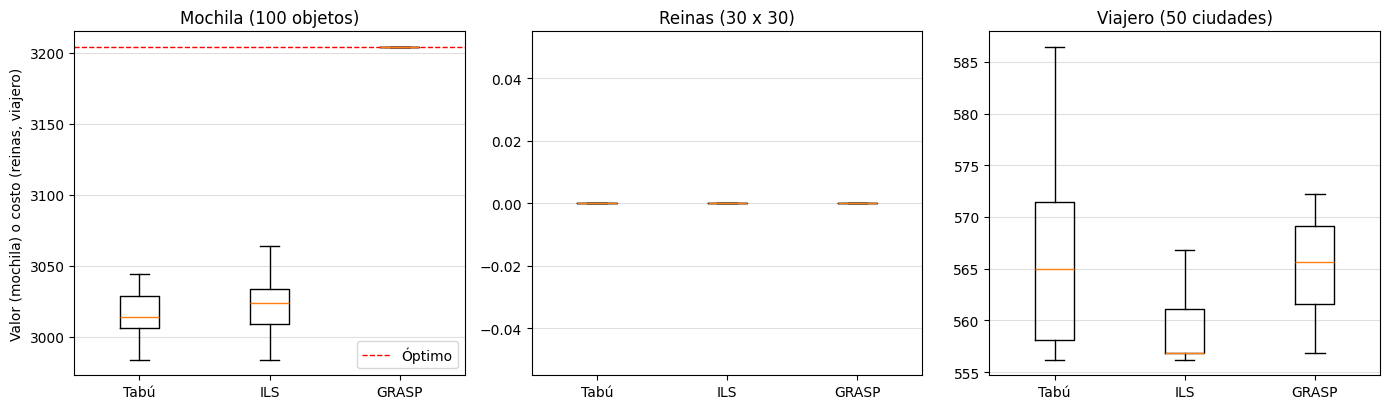

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
for eje, nombre_prob in zip(ejes, problemas):
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    eje.boxplot([[signo * c for c in resultados[(nombre_prob, m)][0]] for m in metodos])
    eje.set_xticks(range(1, len(metodos) + 1))
    eje.set_xticklabels(list(metodos))
    eje.set_title(nombre_prob)
    eje.grid(True, axis='y', alpha=0.4)
ejes[0].axhline(OPTIMO_MOCHILA100, color='red', linestyle='--', linewidth=1, label='Óptimo')
ejes[0].legend()
ejes[0].set_ylabel('Valor (mochila) o costo (reinas, viajero)')
plt.tight_layout()
plt.show()

En la mochila de 100 objetos, ni la búsqueda tabú ni ILS llegan al óptimo de 3204, mientras que GRASP lo encuentra en las 10 semillas. La salida explica la diferencia. Las tres llenan la mochila hasta la capacidad, 2514, pero las soluciones de la búsqueda tabú y de ILS llevan entre 47 y 55 objetos y las de GRASP llevan 69. Como cada objeto vale su peso más 10, el valor de una selección es el peso usado más 10 por cada objeto, y con la mochila llena solo se gana valor metiendo más objetos. Para eso hay que sacar un objeto pesado y meter dos o más livianos en su lugar, un cambio que ningún movimiento *flip* o de intercambio hace en un solo paso. El primer paso de ese camino, sacar el objeto pesado, es un empeoramiento grande, mientras que hay muchos intercambios que empeoran la solución en una o dos unidades, y la búsqueda tabú, que toma siempre el mejor vecino permitido, tiende a escoger estos últimos. GRASP, en cambio, construye las soluciones por razón de valor por peso, que favorece a los objetos livianos, y la búsqueda local termina el trabajo. El capítulo 6 vuelve sobre este problema con vecindarios más grandes.

En las reinas, los tres métodos llegan a cero conflictos en las 10 semillas. En el agente viajero, la búsqueda tabú encuentra el mejor recorrido de la comparación, 556,20, el mismo de ILS, pero su promedio, 567,56, es peor que el de ILS y parecido al de GRASP, y su dispersión es la mayor de los tres. Con el vecindario completo, una parte importante de su presupuesto se va en el descenso inicial desde un recorrido aleatorio. Con 10 semillas y una sola instancia por problema, estas diferencias son indicios; el capítulo 16 trata cómo comparar algoritmos con rigor.